In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import duckdb
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Airline_Delay_Cause.csv")

In [4]:
df.head(5)

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2026,7,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",61.0,25.0,7.58,3.08,...,0.0,9.45,5.0,0.0,3034.0,941.0,937.0,211.0,0.0,945.0
1,2026,7,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",92.0,34.0,10.01,1.19,...,0.0,17.72,2.0,1.0,3163.0,906.0,42.0,324.0,0.0,1891.0
2,2026,7,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",92.0,31.0,9.69,0.87,...,0.0,16.58,1.0,1.0,2613.0,668.0,150.0,123.0,0.0,1672.0
3,2026,7,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",205.0,77.0,28.98,6.17,...,0.0,31.88,7.0,0.0,6531.0,2280.0,717.0,605.0,0.0,2929.0
4,2026,7,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",93.0,26.0,9.63,0.00,...,0.0,14.84,7.0,0.0,2344.0,911.0,0.0,164.0,0.0,1269.0


In [5]:
df.shape

(73284, 21)

In [6]:
df.tail(5)

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
73279,2023,5,ZW,Air Wisconsin Airlines Corp,SCE,"State College, PA: University Park",31.0,4.0,1.00,1.0,...,0.0,1.95,0.0,0.0,319.0,83.0,65.0,2.0,0.0,169.0
73280,2023,5,ZW,Air Wisconsin Airlines Corp,SDF,"Louisville, KY: Louisville Muhammad Ali Intern...",9.0,0.0,0.00,0.0,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
73281,2023,5,ZW,Air Wisconsin Airlines Corp,SGF,"Springfield, MO: Springfield-Branson National",7.0,0.0,0.00,0.0,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
73282,2023,5,ZW,Air Wisconsin Airlines Corp,SYR,"Syracuse, NY: Syracuse Hancock International",30.0,5.0,1.04,0.0,...,0.0,1.50,0.0,0.0,274.0,89.0,0.0,76.0,0.0,109.0
73283,2023,5,ZW,Air Wisconsin Airlines Corp,TYS,"Knoxville, TN: McGhee Tyson",12.0,0.0,0.00,0.0,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
df['carrier_name'].unique()

array(['Endeavor Air Inc.', 'American Airlines Network',
       'Alaska Airlines Network', 'JetBlue Airways',
       'CommuteAir LLC dba CommuteAir', 'Delta Air Lines Network',
       'Frontier Airlines', 'Allegiant Air',
       'GoJet Airlines LLC d/b/a United Express', 'Envoy Air',
       'PSA Airlines Inc.', 'SkyWest Airlines Inc.', 'Piedmont Airlines',
       'Horizon Air', 'United Air Lines Network', 'Southwest Airlines',
       'Mesa Airlines Inc.', 'Republic Airline', 'Spirit Airlines',
       'Hawaiian Airlines Network', 'Air Wisconsin Airlines Corp'],
      dtype=object)

In [8]:
print(len(df['airport_name'].unique()))

386


In [9]:
df_endeavor = df[df["carrier_name"] == "Endeavor Air Inc."]
df_endeavor.head()
df_endeavor.shape

(3925, 21)

In [10]:
arr = df_endeavor['airport_name'].unique()
print(len(arr))

131


In [11]:
df["month"].dtype

dtype('int64')

In [12]:
df.columns

Index(['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name',
       'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct',
       'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted',
       'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay',
       'security_delay', 'late_aircraft_delay'],
      dtype='object')

In [13]:
delays = duckdb.sql("""
    SELECT carrier_name, SUM(arr_del15) AS total_delay
    FROM df
    GROUP BY carrier_name
    ORDER BY total_delay DESC
""").df()

In [14]:
delays.head()

,carrier_name,total_delay
0,Southwest Airlines,1001275.0
1,American Airlines Network,784792.0
2,Delta Air Lines Network,586724.0
3,United Air Lines Network,513775.0
4,SkyWest Airlines Inc.,486664.0


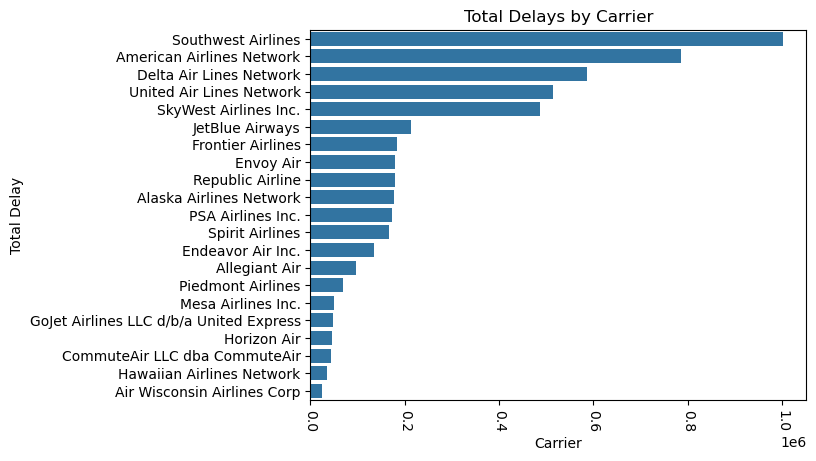

In [15]:
sns.barplot(
    data=delays,
    x="total_delay",
    y="carrier_name"
)
plt.xticks(rotation = -90)
plt.xlabel('Carrier')
plt.ylabel('Total Delay')
plt.title("Total Delays by Carrier")
plt.show()

In [16]:
delay_columns = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"
]

delay_totals = df[delay_columns].sum()

delay_percentages = delay_totals / delay_totals.sum() * 100

print(delay_percentages)

carrier_delay          33.586723
weather_delay           6.145547
nas_delay              19.544298
security_delay          0.154047
late_aircraft_delay    40.569386
dtype: float64


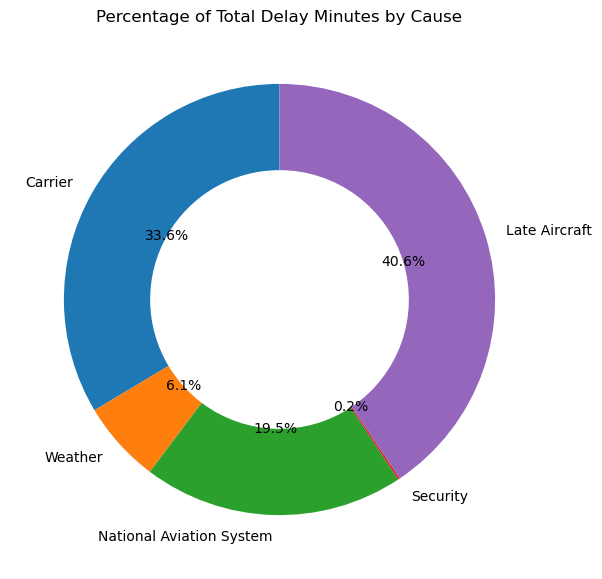

In [17]:
labels = [
    "Carrier",
    "Weather",
    "National Aviation System",
    "Security",
    "Late Aircraft"
]

fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    delay_totals,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

ax.set_title("Percentage of Total Delay Minutes by Cause")

plt.show()

NAS delays are delays due to the broader aviation system rather than the airline itself. Some causes of NAS delays:
*ATC - too many airplanes in the airspace, requring planes to wait.
*Airport congestion - too many airplanes arriving or departing at the same time.
*Non-extreme weather - weather that reduces visibility such as fog or low visibility.

In [21]:
monthly_delays = duckdb.sql("""
    SELECT
        month,
        SUM(arr_flights) AS total_flights,
        SUM(arr_del15) AS delayed_flights,
        ROUND(
            100.0 * SUM(arr_del15) /
            NULLIF(SUM(arr_flights), 0),
            2
        ) AS delay_rate
    FROM df
    GROUP BY month
    ORDER BY month
""").df()

In [22]:
monthly_delays.head()

,month,total_flights,delayed_flights,delay_rate
0,1,1784391.0,362852.0,20.33
1,2,1681057.0,308792.0,18.37
2,3,1969218.0,412652.0,20.96
3,4,1924678.0,370780.0,19.26
4,5,2610852.0,574461.0,22.00


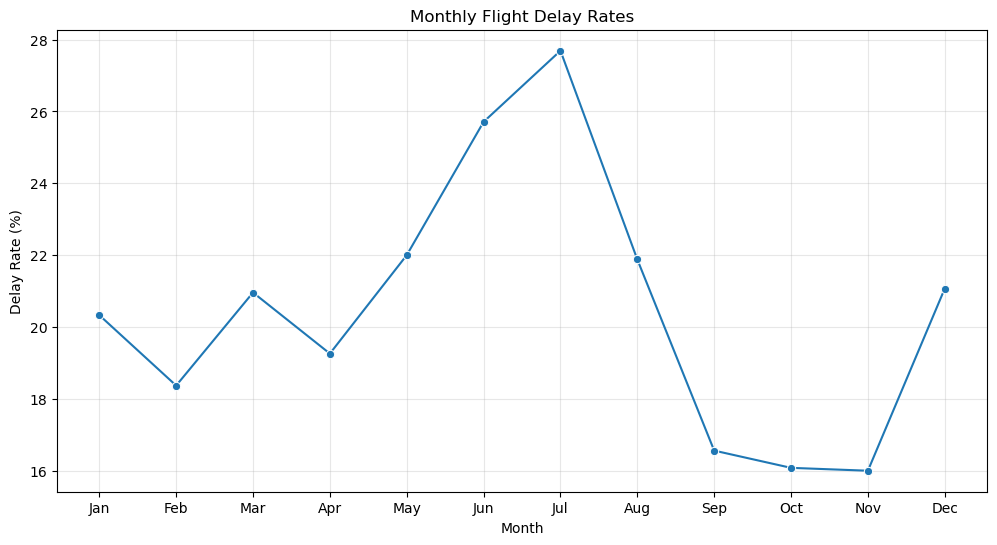

In [23]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_delays,
    x="month",
    y="delay_rate",
    marker="o"
)

plt.title("Monthly Flight Delay Rates")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(alpha=0.3)
plt.show()

In [26]:
yearly_monthly_delays = duckdb.sql("""
    SELECT
        year,
        month,
        ROUND(
            100.0 * SUM(arr_del15) /
            NULLIF(SUM(arr_flights), 0),
            2
        ) AS delay_rate
    FROM df
    GROUP BY year, month
    ORDER BY year, month
""").df()

yearly_monthly_delays.head()

,year,month,delay_rate
0,2023,5,17.92
1,2023,6,26.18
2,2023,7,27.51
3,2023,8,21.07
4,2023,9,18.27


In [27]:
heatmap_data = yearly_monthly_delays.pivot(
    index="year",
    columns="month",
    values="delay_rate"
)

heatmap_data = heatmap_data.reindex(columns=range(1, 13))

heatmap_data.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

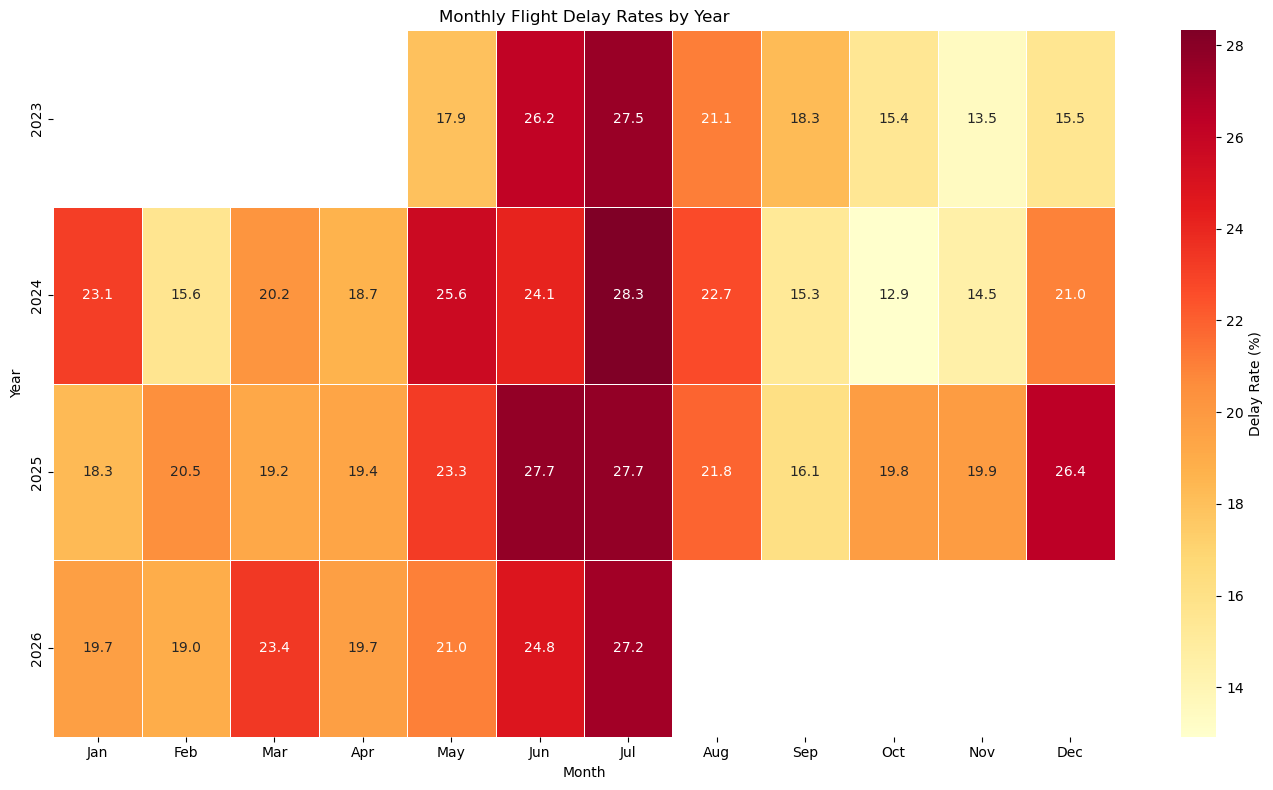

In [28]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Delay Rate (%)"}
)

plt.title("Monthly Flight Delay Rates by Year")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()